In [2]:
import warnings; warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             silhouette_score, ConfusionMatrixDisplay)

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})

In [3]:
path ="./CC GENERAL.csv"
raw = pd.read_csv(path)
print(path, raw.shape)
print(raw.isna().sum()[raw.isna().sum() > 0])
raw.describe().T.round(2)

./CC GENERAL.csv (8950, 18)
CREDIT_LIMIT          1
MINIMUM_PAYMENTS    313
dtype: int64


,count,mean,std,min,25%,50%,75%,max
BALANCE,8950.0,1564.47,2081.53,0.00,128.28,873.39,2054.14,19043.14
BALANCE_FREQUENCY,8950.0,0.88,0.24,0.00,0.89,1.00,1.00,1.00
PURCHASES,8950.0,1003.20,2136.63,0.00,39.64,361.28,1110.13,49039.57
ONEOFF_PURCHASES,8950.0,592.44,1659.89,0.00,0.00,38.00,577.40,40761.25
INSTALLMENTS_PURCHASES,8950.0,411.07,904.34,0.00,0.00,89.00,468.64,22500.00
CASH_ADVANCE,8950.0,978.87,2097.16,0.00,0.00,0.00,1113.82,47137.21
PURCHASES_FREQUENCY,8950.0,0.49,0.40,0.00,0.08,0.50,0.92,1.00
ONEOFF_PURCHASES_FREQUENCY,8950.0,0.20,0.30,0.00,0.00,0.08,0.30,1.00
PURCHASES_INSTALLMENTS_FREQUENCY,8950.0,0.36,0.40,0.00,0.00,0.17,0.75,1.00
CASH_ADVANCE_FREQUENCY,8950.0,0.14,0.20,0.00,0.00,0.00,0.22,1.50


In [6]:
df = raw.dropna(subset=["CREDIT_LIMIT"]).reset_index(drop=True)
cust_id = df.pop("CUST_ID")
ALL_FEATURES = df.columns.tolist()
print(len(ALL_FEATURES), "features")

17 features


In [7]:
def pct_labels(d):
    cl, pu = d["CREDIT_LIMIT"].quantile(.7), d["PURCHASES"].quantile(.7)
    print(f"CREDIT_LIMIT >= {cl:,.0f} and PURCHASES >= {pu:,.0f}")
    return ((d["CREDIT_LIMIT"] >= cl) & (d["PURCHASES"] >= pu)).astype(int)

Xk = StandardScaler().fit_transform(np.log1p(df.fillna(df.median())))

ks = range(2, 6)
sil = {k: silhouette_score(Xk, KMeans(k, n_init=10, random_state=SEED).fit_predict(Xk),
                           sample_size=3000, random_state=SEED) for k in ks}
print("Silhouette by k:", {k: round(v, 3) for k, v in sil.items()})

km = KMeans(2, n_init=10, random_state=SEED).fit(Xk)
rel = [df["CREDIT_LIMIT"][km.labels_ == c].mean() / df["CREDIT_LIMIT"].mean()
       + df["PURCHASES"][km.labels_ == c].mean() / df["PURCHASES"].mean() for c in (0, 1)]
y_km = pd.Series((km.labels_ == int(np.argmax(rel))).astype(int), index=df.index)
y_pct = pct_labels(df)

LABELS = {"percentile": y_pct, "kmeans": y_km}
print("\nHigh-value share:", {k: f"{v.mean():.1%}" for k, v in LABELS.items()})
display(pd.crosstab(y_pct, y_km, rownames=["percentile"], colnames=["kmeans"]))

Silhouette by k: {2: 0.257, 3: 0.231, 4: 0.215, 5: 0.23}
CREDIT_LIMIT >= 6,000 and PURCHASES >= 894

High-value share: {'percentile': '14.3%', 'kmeans': '65.3%'}


kmeans,0,1
percentile,,
0,3027,4644
1,79,1199


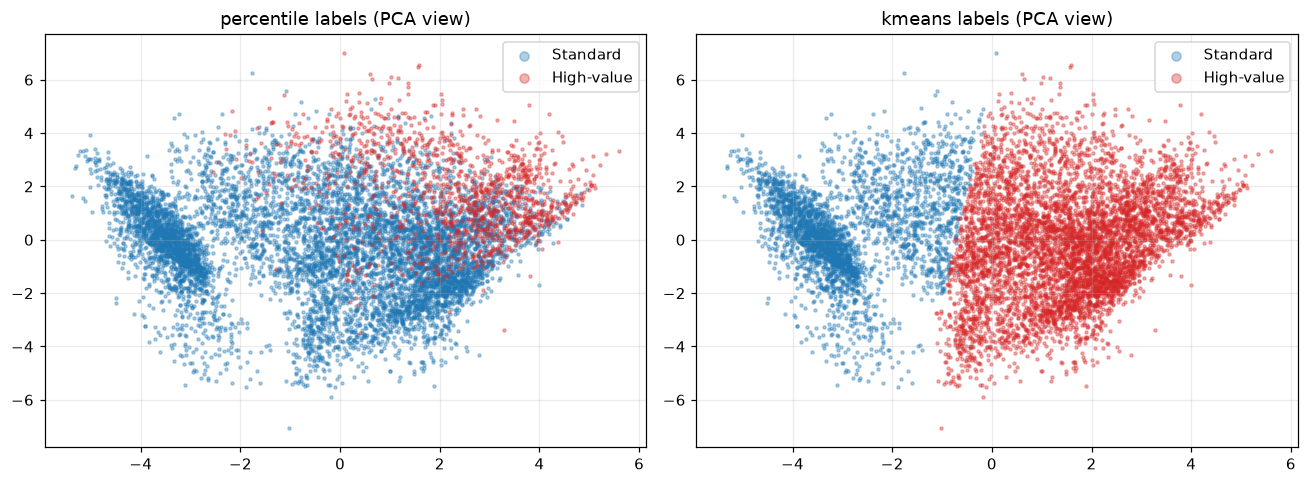

,CREDIT_LIMIT,PURCHASES,BALANCE,PAYMENTS,CASH_ADVANCE,PURCHASES_FREQUENCY
K-means: Standard,3000.0,0.00,1593.22,855.46,1337.72,0.00
K-means: High-value,3400.0,721.78,388.87,857.98,0.00,0.83


In [8]:
p = PCA(2, random_state=SEED).fit_transform(Xk)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, (n, y_) in zip(ax, LABELS.items()):
    a.scatter(p[y_ == 0, 0], p[y_ == 0, 1], s=4, alpha=.35, c="tab:blue", label="Standard")
    a.scatter(p[y_ == 1, 0], p[y_ == 1, 1], s=4, alpha=.35, c="tab:red", label="High-value")
    a.set_title(f"{n} labels (PCA view)"); a.legend(markerscale=3)
plt.tight_layout(); plt.show()

med = df.groupby(y_km)[["CREDIT_LIMIT", "PURCHASES", "BALANCE", "PAYMENTS", "CASH_ADVANCE", "PURCHASES_FREQUENCY"]].median()
med.index = ["K-means: Standard", "K-means: High-value"]
med.round(2)

In [9]:
A_FEATS = ["CREDIT_LIMIT", "PURCHASES"]

def prep_2d(y):
    d = df[A_FEATS].copy(); d["y"] = y
    d = d[(d[A_FEATS] <= d[A_FEATS].quantile(.99)).all(axis=1)]
    X = StandardScaler().fit_transform(np.log1p(d[A_FEATS])); t = d["y"].values
    dist = np.abs(LogisticRegression(class_weight="balanced").fit(X, t).decision_function(X))
    keep = dist >= np.quantile(dist, .25)
    X, t = X[keep], t[keep]
    X, _, t, _ = train_test_split(X, t, train_size=min(1500, len(t) - 1), stratify=t, random_state=SEED)
    return X, t

def plot_svm(ax, clf, X, y, title):
    w, b = clf.coef_[0], clf.intercept_[0]
    width = 2 / np.linalg.norm(w)
    x0, x1 = X[:, 0].min() - .3, X[:, 0].max() + .3
    xs = np.linspace(x0, x1, 200)
    line = lambda off: -(w[0] * xs + b - off) / w[1]
    ax.scatter(*X[y == 0].T, c="tab:blue", s=10, alpha=.45, label="Standard")
    ax.scatter(*X[y == 1].T, c="tab:red", s=10, alpha=.45, label="High-value")
    ax.fill_between(xs, line(-1), line(1), color="gold", alpha=.18, label="Margin")
    ax.plot(xs, line(0), "k-", lw=2, label="Boundary")
    ax.plot(xs, line(1), "k--", lw=1); ax.plot(xs, line(-1), "k--", lw=1)
    sv = clf.support_vectors_
    ax.scatter(*sv.T, s=70, facecolors="none", edgecolors="k", label=f"Support vectors ({len(sv)})")
    ax.set_xlim(x0, x1); ax.set_ylim(X[:, 1].min() - .3, X[:, 1].max() + .3)
    ax.set_xlabel("CREDIT_LIMIT (log, std)"); ax.set_ylabel("PURCHASES (log, std)")
    ax.set_title(f"{title}\nmargin width = {width:.3f}")
    return width

DATA_A = {n: prep_2d(y_) for n, y_ in LABELS.items()}

percentile: w=[1.232 1.97 ], b=-2.437, ||w||=2.324, margin=2/||w||=0.861, SVs=13
kmeans: w=[-0.209  1.172], b=0.479, ||w||=1.190, margin=2/||w||=1.680, SVs=191


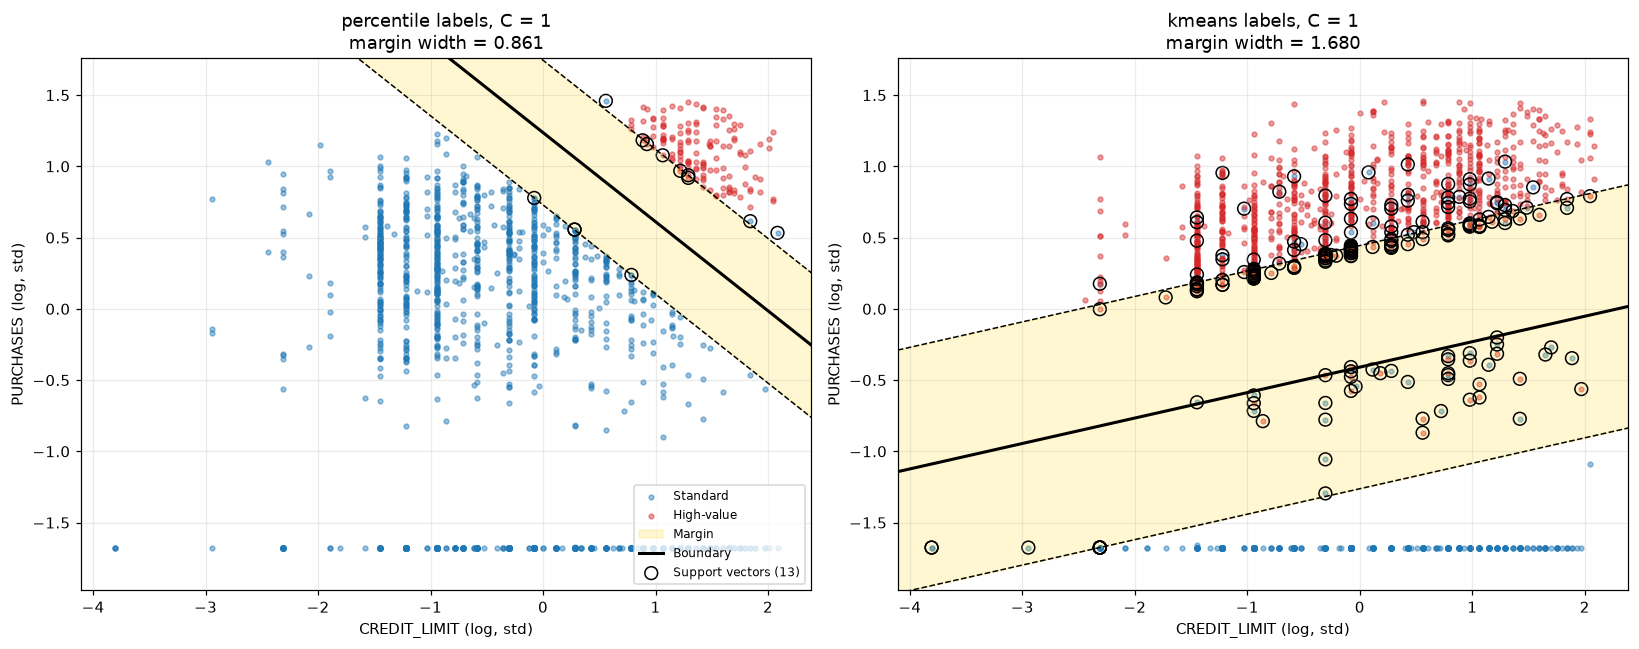

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (n, (X, t)) in zip(axes, DATA_A.items()):
    clf = SVC(kernel="linear", C=1).fit(X, t)
    plot_svm(ax, clf, X, t, f"{n} labels, C = 1")
    w = clf.coef_[0]
    print(f"{n}: w={w.round(3)}, b={clf.intercept_[0]:.3f}, ||w||={np.linalg.norm(w):.3f}, "
          f"margin=2/||w||={2/np.linalg.norm(w):.3f}, SVs={len(clf.support_vectors_)}")
axes[0].legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

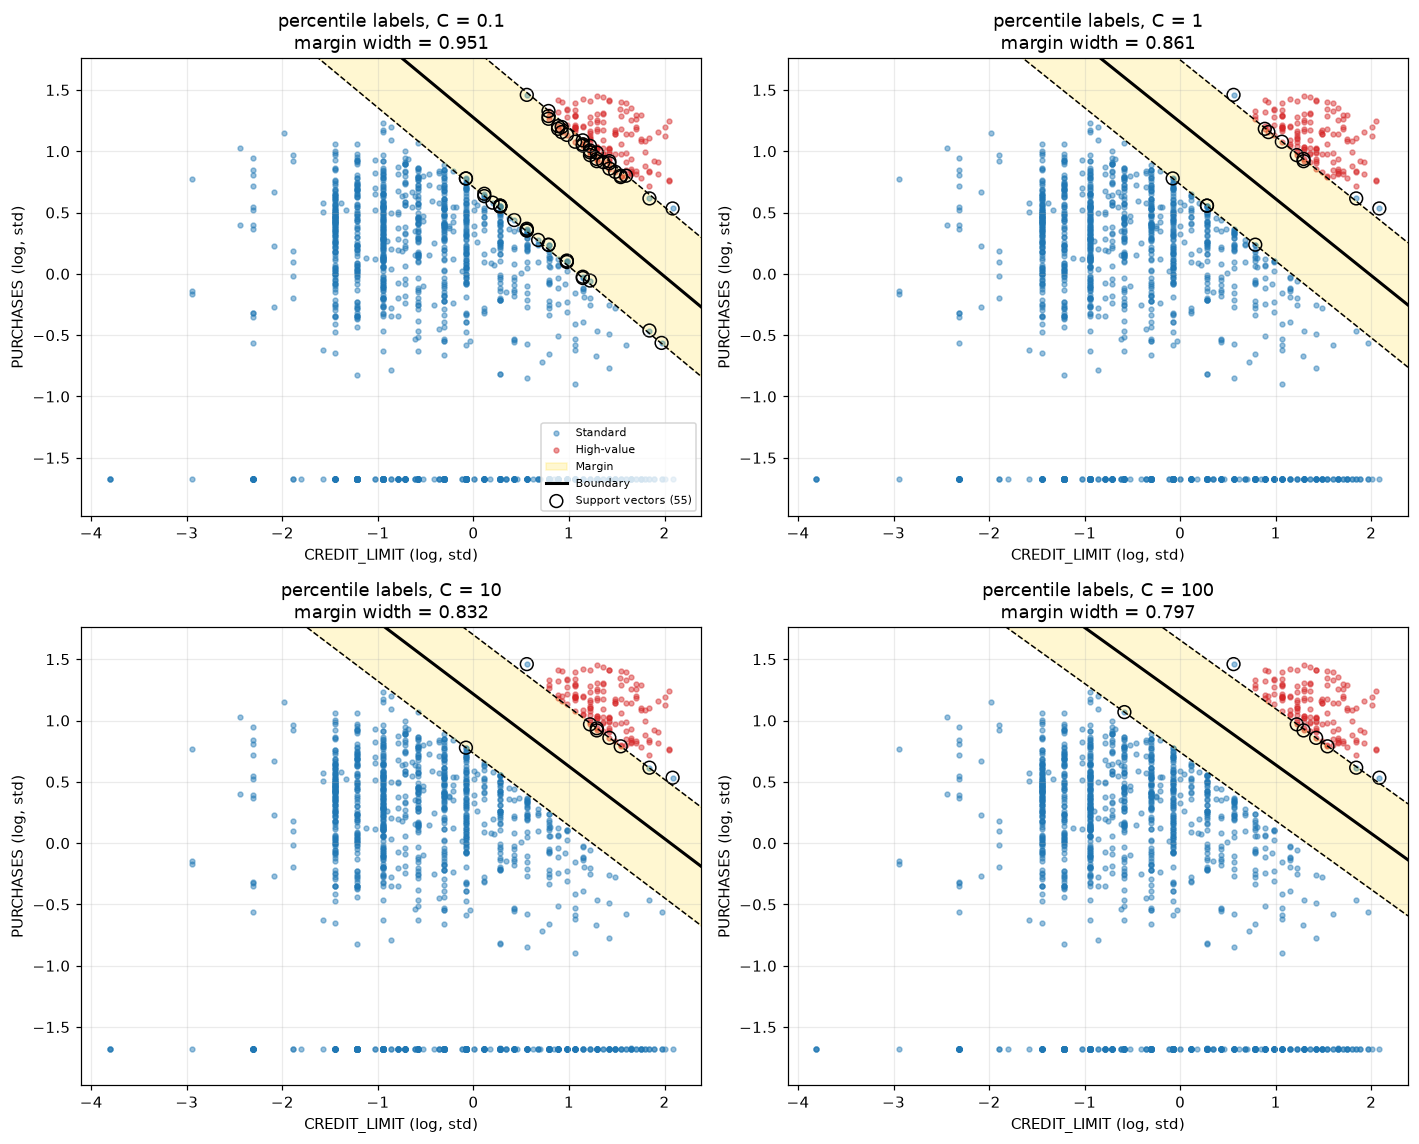

,margin width,support vectors,train errors,train accuracy
C,,,,
0.1,0.951,55,3,0.998
1.0,0.861,13,3,0.998
10.0,0.832,9,3,0.998
100.0,0.797,8,3,0.998


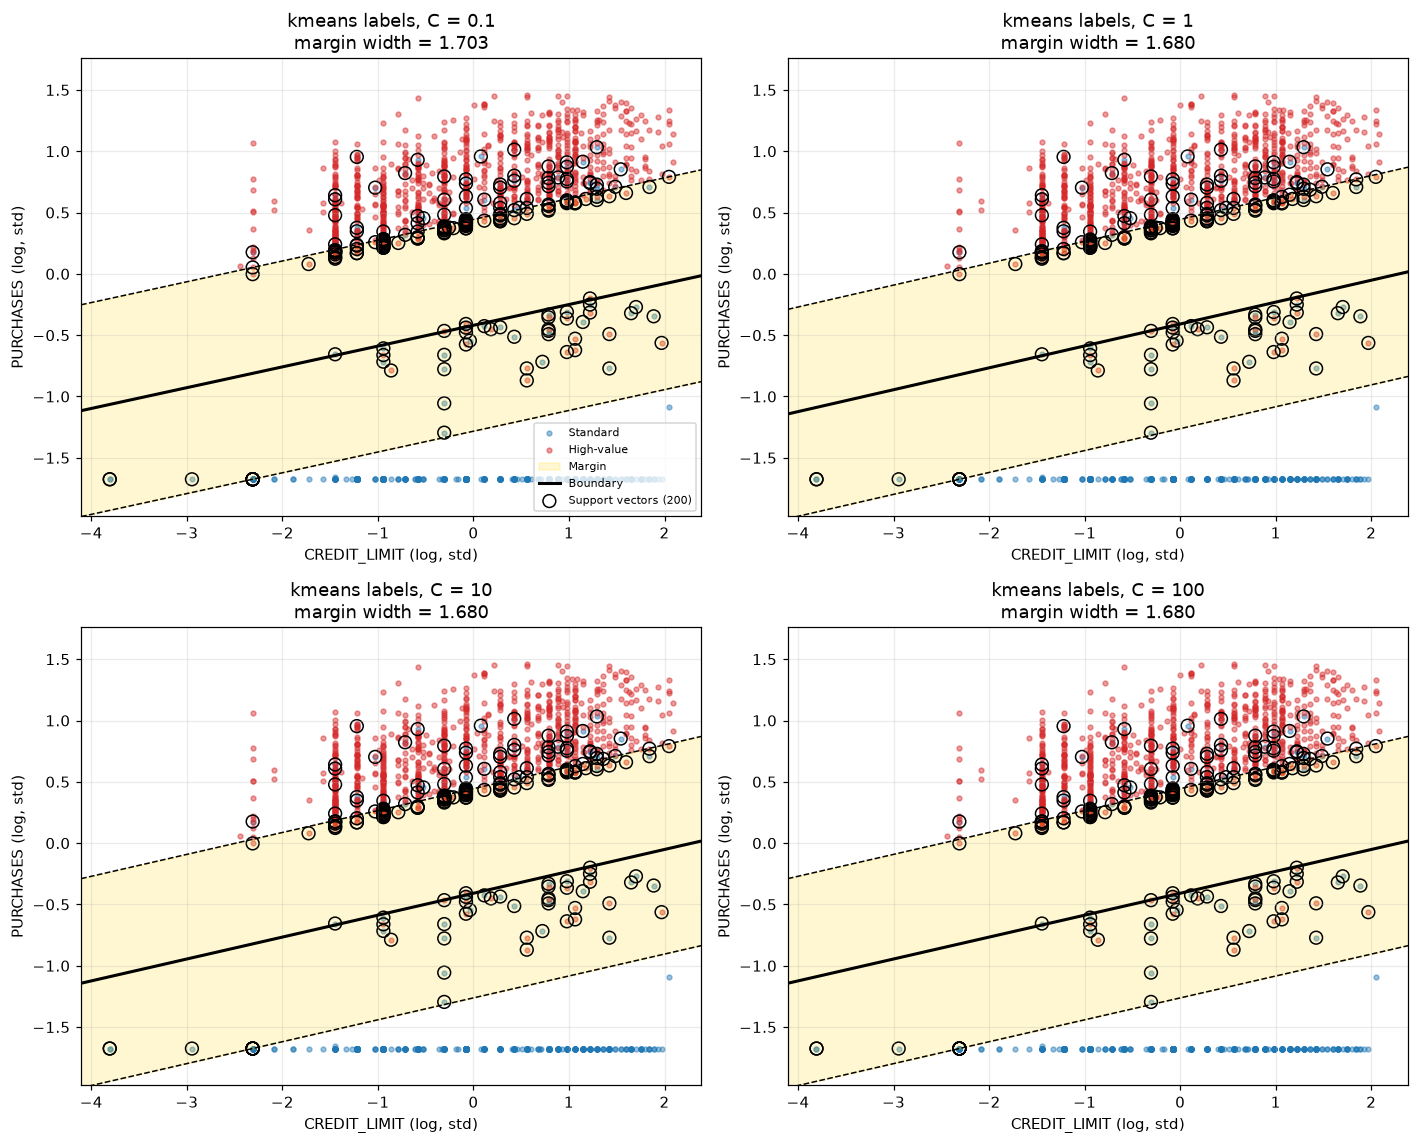

,margin width,support vectors,train errors,train accuracy
C,,,,
0.1,1.703,200,81,0.9460
1.0,1.680,191,83,0.9447
10.0,1.680,191,83,0.9447
100.0,1.680,192,83,0.9447


In [11]:
C_LIST = [0.1, 1, 10, 100]
for n, (X, t) in DATA_A.items():
    fig, axes = plt.subplots(2, 2, figsize=(13, 10.5))
    rows = []
    for ax, C in zip(axes.ravel(), C_LIST):
        clf = SVC(kernel="linear", C=C).fit(X, t)
        width = plot_svm(ax, clf, X, t, f"{n} labels, C = {C}")
        err = int((clf.predict(X) != t).sum())
        rows.append({"C": C, "margin width": round(width, 3), "support vectors": len(clf.support_vectors_),
                     "train errors": err, "train accuracy": round(1 - err / len(t), 4)})
    axes[0, 0].legend(loc="lower right", fontsize=7)
    plt.tight_layout(); plt.show()
    display(pd.DataFrame(rows).set_index("C"))

In [12]:
C_GRID = [0.001, 0.01, 0.1, 1, 10, 100]

def make_pipe(clf):
    return Pipeline([("imp", SimpleImputer(strategy="median")),
                     ("log", FunctionTransformer(np.log1p)),
                     ("sc", StandardScaler()), ("clf", clf)])

def scores(t, p):
    return {"accuracy": accuracy_score(t, p), "precision": precision_score(t, p, zero_division=0),
            "recall": recall_score(t, p, zero_division=0), "F1": f1_score(t, p, zero_division=0)}

MODELS = {"Linear SVM": lambda C: SVC(kernel="linear", C=C, class_weight="balanced"),
          "Logistic Regression": lambda C: LogisticRegression(C=C, class_weight="balanced", max_iter=5000)}

def run_experiment(features, y, name):
    X_tmp, X_te, y_tmp, y_te = train_test_split(df[features], y, test_size=.2, stratify=y, random_state=SEED)
    X_tr, X_va, y_tr, y_va = train_test_split(X_tmp, y_tmp, test_size=.25, stratify=y_tmp, random_state=SEED)
    print(f"{name}: train/val/test = {len(X_tr)}/{len(X_va)}/{len(X_te)}")
    tune, best, res = [], {}, {}
    for m, factory in MODELS.items():
        top = (-1, None, None)
        for C in C_GRID:
            pipe = make_pipe(factory(C)).fit(X_tr, y_tr)
            f1 = f1_score(y_va, pipe.predict(X_va))
            tune.append({"model": m, "C": C, "val F1": round(f1, 4)})
            if f1 > top[0]: top = (f1, C, pipe)
        best[m] = (top[1], top[2])
        res[f"{m} (C={top[1]})"] = scores(y_te, top[2].predict(X_te))
    return {"name": name, "features": features, "y": y, "X_tr": X_tr, "X_te": X_te, "y_te": y_te,
            "tuning": pd.DataFrame(tune).pivot(index="C", columns="model", values="val F1"),
            "best": best, "results": pd.DataFrame(res).T.round(4)}

NOLEAK = [c for c in ALL_FEATURES if c not in ("CREDIT_LIMIT", "PURCHASES")]
EXPS = {
    "percentile | all features": run_experiment(ALL_FEATURES, y_pct, "percentile | all features"),
    "percentile | no leakage":   run_experiment(NOLEAK, y_pct, "percentile | no leakage"),
    "kmeans | all features":     run_experiment(ALL_FEATURES, y_km, "kmeans | all features"),
}

percentile | all features: train/val/test = 5369/1790/1790
percentile | no leakage: train/val/test = 5369/1790/1790
kmeans | all features: train/val/test = 5369/1790/1790


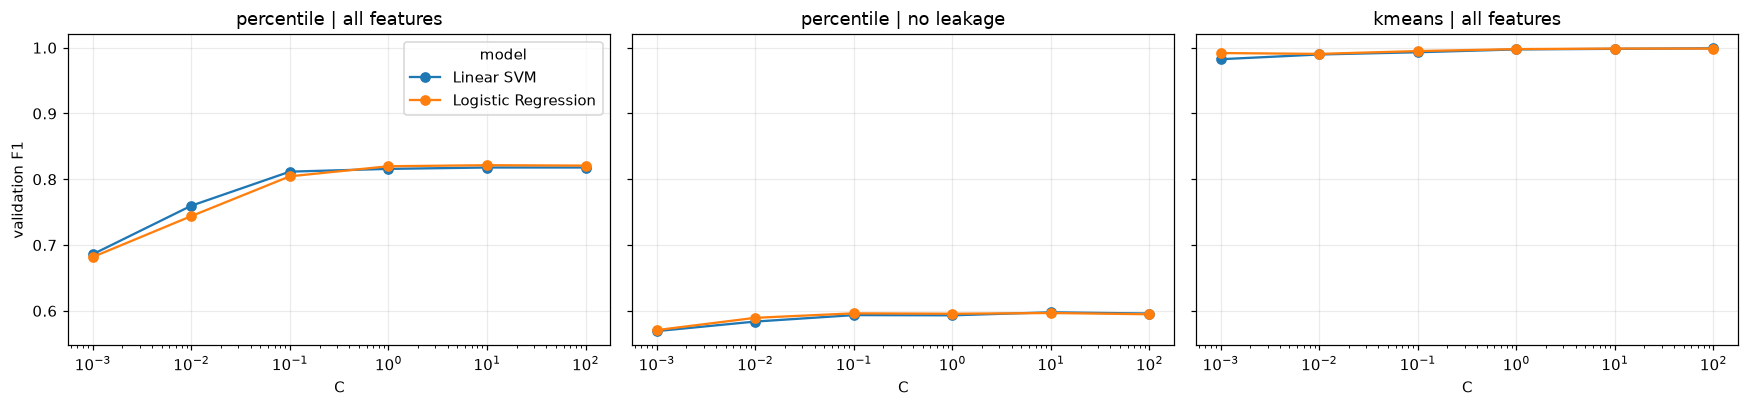

accuracy  precision  \
percentile | all features Linear SVM (C=10)             0.9296     0.6816   
                          Logistic Regression (C=10)    0.9313     0.6928   
percentile | no leakage   Linear SVM (C=10)             0.8050     0.4118   
                          Logistic Regression (C=10)    0.8101     0.4189   
kmeans | all features     Linear SVM (C=100)            0.9994     1.0000   
                          Logistic Regression (C=10)    0.9994     1.0000   

                                                      recall      F1  
percentile | all features Linear SVM (C=10)           0.9531  0.7948  
                          Logistic Regression (C=10)  0.9336  0.7953  
percentile | no leakage   Linear SVM (C=10)           0.8477  0.5543  
                          Logistic Regression (C=10)  0.8477  0.5607  
kmeans | all features     Linear SVM (C=100)          0.9991  0.9996  
                          Logistic Regression (C=10)  0.9991  0.9996

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for ax, (n, e) in zip(axes, EXPS.items()):
    e["tuning"].plot(ax=ax, marker="o", logx=True, title=n, legend=ax is axes[0])
    ax.set_ylabel("validation F1")
plt.tight_layout(); plt.show()

summary = pd.concat({n: e["results"] for n, e in EXPS.items()})
summary

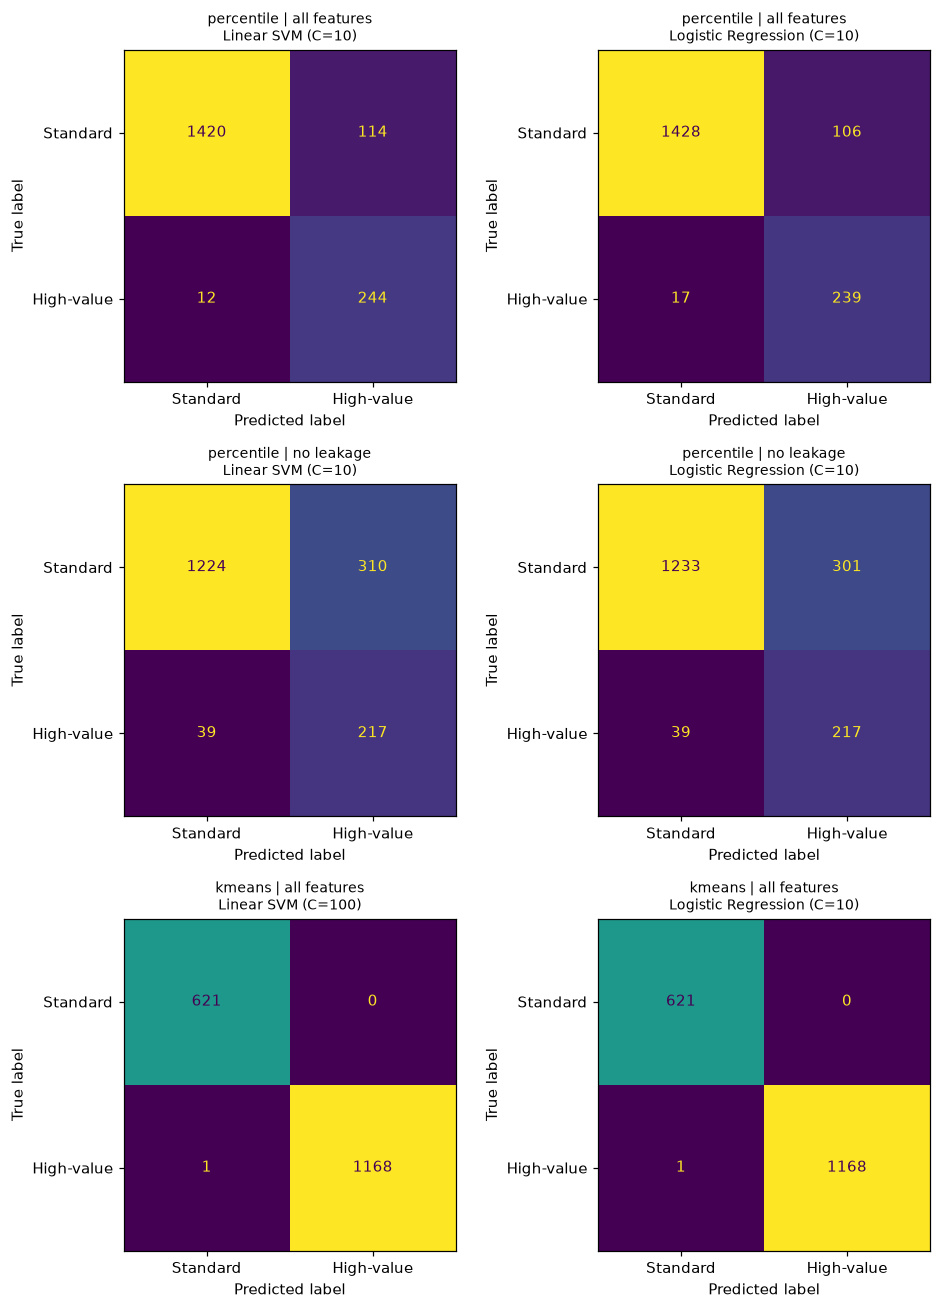

In [14]:
fig, axes = plt.subplots(3, 2, figsize=(9, 12))
for r, (n, e) in enumerate(EXPS.items()):
    for c, (m, (C, pipe)) in enumerate(e["best"].items()):
        ConfusionMatrixDisplay.from_predictions(e["y_te"], pipe.predict(e["X_te"]), ax=axes[r, c],
                                                display_labels=["Standard", "High-value"], colorbar=False)
        axes[r, c].set_title(f"{n}\n{m} (C={C})", fontsize=9); axes[r, c].grid(False)
plt.tight_layout(); plt.show()

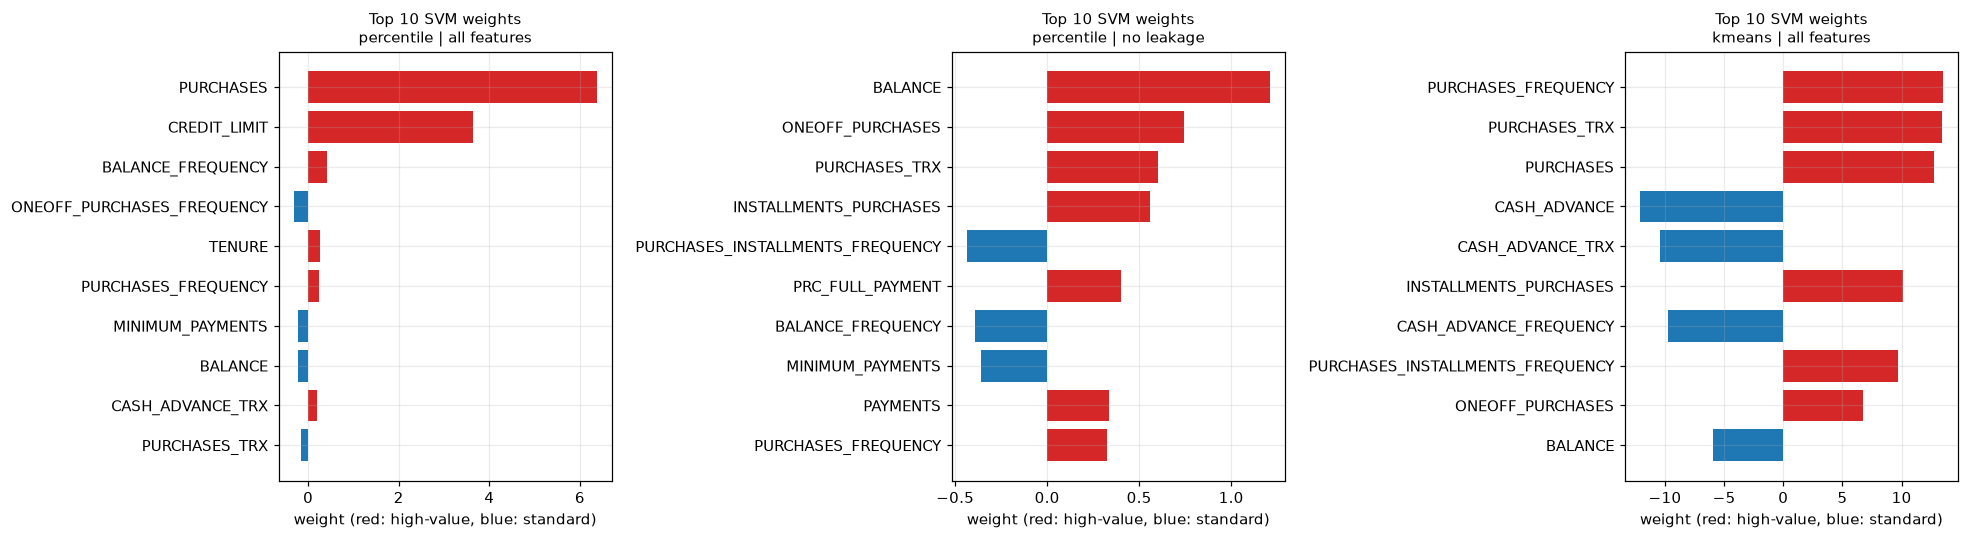

,percentile | all features,percentile | no leakage,kmeans | all features
BALANCE,-0.213,1.21,-5.96
BALANCE_FREQUENCY,0.415,-0.393,-
CASH_ADVANCE,-,-,-12.103
CASH_ADVANCE_FREQUENCY,-,-,-9.739
CASH_ADVANCE_TRX,0.19,-,-10.439
CREDIT_LIMIT,3.641,-,-
INSTALLMENTS_PURCHASES,-,0.556,10.101
MINIMUM_PAYMENTS,-0.229,-0.361,-
ONEOFF_PURCHASES,-,0.743,6.751
ONEOFF_PURCHASES_FREQUENCY,-0.316,-,-


In [15]:
def top_weights(e, k=10):
    w = pd.Series(e["best"]["Linear SVM"][1].named_steps["clf"].coef_[0], index=e["features"])
    return w.reindex(w.abs().sort_values(ascending=False).index).head(k)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (n, e) in zip(axes, EXPS.items()):
    tw = top_weights(e)[::-1]
    ax.barh(tw.index, tw.values, color=np.where(tw.values > 0, "tab:red", "tab:blue"))
    ax.set_title(f"Top 10 SVM weights\n{n}", fontsize=10)
    ax.set_xlabel("weight (red: high-value, blue: standard)")
plt.tight_layout(); plt.show()

pd.DataFrame({n: top_weights(e) for n, e in EXPS.items()}).round(3).fillna("-")

In [16]:
profile_cols = ["CREDIT_LIMIT", "PURCHASES", "BALANCE", "PAYMENTS", "PURCHASES_TRX", "PURCHASES_FREQUENCY",
                "INSTALLMENTS_PURCHASES", "ONEOFF_PURCHASES", "CASH_ADVANCE", "PRC_FULL_PAYMENT", "TENURE"]
BORDER = {"percentile | no leakage": EXPS["percentile | no leakage"],
          "kmeans | all features": EXPS["kmeans | all features"]}
SCORES = {}

for n, e in BORDER.items():
    C, pipe = e["best"]["Linear SVM"]
    y_ = e["y"]
    n_sv = len(pipe.named_steps["clf"].support_)
    print(f"\n=== {n} (C={C}): {n_sv} support vectors = {n_sv/len(e['X_tr']):.1%} of training set")
    s = pd.Series(pipe.decision_function(df[e["features"]]), index=df.index)
    SCORES[n] = s
    grp = pd.Series("Standard (confident)", index=df.index)
    grp[(y_ == 1) & (s >= 1)] = "High-value (confident)"
    grp[s.abs() < 1] = "Borderline (inside margin)"
    print(grp.value_counts().to_string())
    display(df.groupby(grp)[profile_cols].median().round(2).T)


=== percentile | no leakage (C=10): 1881 support vectors = 35.0% of training set
Standard (confident)          5474
Borderline (inside margin)    2674
High-value (confident)         801


,Borderline (inside margin),High-value (confident),Standard (confident)
CREDIT_LIMIT,4000.00,9000.00,2500.00
PURCHASES,853.98,3442.08,99.00
BALANCE,991.86,2380.29,675.67
PAYMENTS,1181.23,3327.96,548.74
PURCHASES_TRX,12.00,43.00,2.00
PURCHASES_FREQUENCY,0.67,1.00,0.13
INSTALLMENTS_PURCHASES,238.95,1069.20,0.00
ONEOFF_PURCHASES,368.72,2038.24,0.00
CASH_ADVANCE,0.00,0.00,76.50
PRC_FULL_PAYMENT,0.00,0.00,0.00



=== kmeans | all features (C=100): 26 support vectors = 0.5% of training set
High-value (confident)        5817
Standard (confident)          3099
Borderline (inside margin)      33


,Borderline (inside margin),High-value (confident),Standard (confident)
CREDIT_LIMIT,1500.00,3400.00,3000.00
PURCHASES,151.64,726.89,0.00
BALANCE,1060.27,383.45,1594.73
PAYMENTS,577.42,858.81,856.20
PURCHASES_TRX,1.00,12.00,0.00
PURCHASES_FREQUENCY,0.10,0.83,0.00
INSTALLMENTS_PURCHASES,0.00,308.00,0.00
ONEOFF_PURCHASES,114.00,221.61,0.00
CASH_ADVANCE,0.00,0.00,1343.02
PRC_FULL_PAYMENT,0.00,0.00,0.00



=== percentile | no leakage: 10 most borderline customers


,CUST_ID,label,svm_score,CREDIT_LIMIT,PURCHASES,PAYMENTS,PURCHASES_TRX
327,C10338,0,-0.000,2500.0,678.00,1926.318530,12
2361,C12434,1,0.001,16500.0,1168.75,3906.738592,11
6417,C16594,0,-0.001,4000.0,478.32,1429.176523,8
1736,C11795,1,-0.002,10500.0,4900.00,615.450902,7
5059,C15201,0,0.002,5000.0,279.71,8627.985927,3
2715,C12793,1,0.002,6000.0,985.20,1670.869438,19
633,C10658,0,0.003,3000.0,733.35,6801.933334,11
3864,C13973,1,-0.003,9500.0,1548.37,1105.365158,21
6469,C16647,0,-0.004,1900.0,1163.49,607.122812,20
3595,C13696,0,-0.005,6000.0,649.00,624.293646,19


Upgrade candidates (labelled standard, scored high-value): 1372


,CUST_ID,label,svm_score,CREDIT_LIMIT,PURCHASES,PAYMENTS,PURCHASES_TRX
1991,C12054,0,4.424,3000.0,15704.04,14399.703180,185
3105,C13195,0,3.781,4000.0,8754.59,8648.305093,116
1423,C11471,0,3.713,4000.0,8751.49,8622.953253,63
6389,C16565,0,3.672,5000.0,10915.37,12612.668240,93
4542,C14667,0,3.656,4500.0,11522.90,11082.514290,68
4206,C14324,0,3.494,4500.0,9751.90,8418.403666,115
295,C10306,0,3.456,2900.0,5758.71,7943.570210,48
3948,C14059,0,3.343,4500.0,6228.01,6052.323160,117
5613,C15770,0,3.179,5200.0,5634.56,5831.664538,104
7276,C17473,0,3.130,5500.0,11577.00,12148.503510,97



=== kmeans | all features: 10 most borderline customers


,CUST_ID,label,svm_score,CREDIT_LIMIT,PURCHASES,PAYMENTS,PURCHASES_TRX
3621,C13724,1,0.006,1200.0,370.00,1483.573731,1
1722,C11779,0,-0.020,1500.0,484.47,1086.417545,9
6471,C16650,1,0.103,1000.0,108.40,2068.816672,4
5385,C15539,1,0.118,2500.0,120.09,368.725300,1
5169,C15314,1,-0.233,8000.0,114.00,577.415935,2
711,C10738,1,-0.265,6000.0,375.57,779.057364,3
5919,C16086,1,0.274,1200.0,334.48,634.297592,6
4390,C14513,1,-0.309,1500.0,79.00,357.720268,1
7847,C18061,1,0.322,1200.0,10.79,918.160924,1
7067,C17260,1,0.433,3000.0,209.62,559.604995,8


Upgrade candidates (labelled standard, scored high-value): 0


,CUST_ID,label,svm_score,CREDIT_LIMIT,PURCHASES,PAYMENTS,PURCHASES_TRX


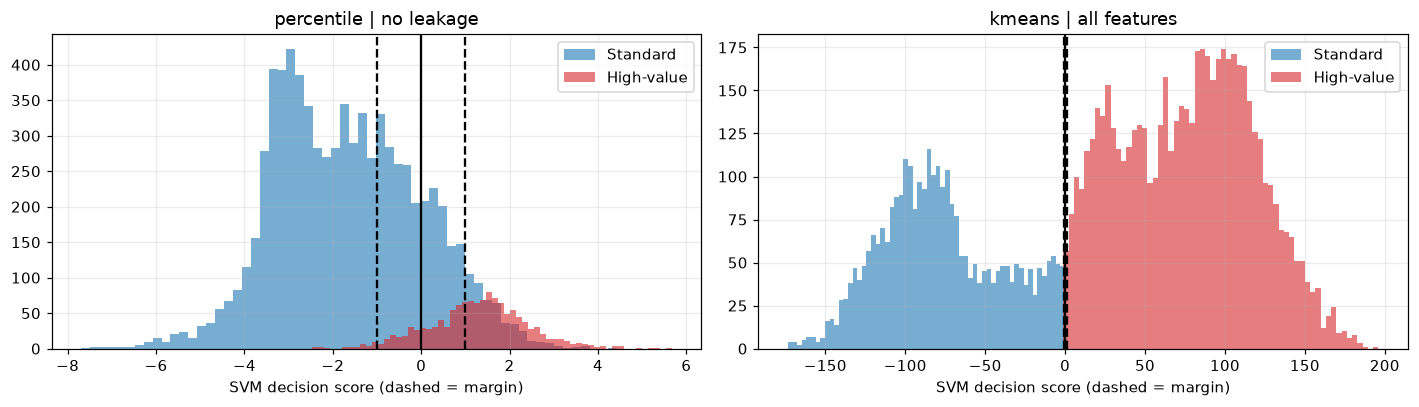

In [17]:
for n, s in SCORES.items():
    y_ = BORDER[n]["y"]
    tbl = pd.concat([cust_id, y_.rename("label"), s.rename("svm_score").round(3),
                     df[["CREDIT_LIMIT", "PURCHASES", "PAYMENTS", "PURCHASES_TRX"]]], axis=1)
    print(f"\n=== {n}: 10 most borderline customers")
    display(tbl.reindex(tbl["svm_score"].abs().sort_values().index).head(10))
    up = tbl[(tbl["label"] == 0) & (tbl["svm_score"] > 0)].sort_values("svm_score", ascending=False)
    print(f"Upgrade candidates (labelled standard, scored high-value): {len(up)}")
    display(up.head(10))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, (n, s) in zip(axes, SCORES.items()):
    y_ = BORDER[n]["y"]
    ax.hist(s[y_ == 0], bins=60, alpha=.6, color="tab:blue", label="Standard")
    ax.hist(s[y_ == 1], bins=60, alpha=.6, color="tab:red", label="High-value")
    for v, ls in [(0, "-"), (-1, "--"), (1, "--")]: ax.axvline(v, c="k", ls=ls)
    ax.set_title(n); ax.set_xlabel("SVM decision score (dashed = margin)"); ax.legend()
plt.tight_layout(); plt.show()